# Departure-time uncertainty: offline vs online scheduling

Every earlier result assumed **perfect information**: the LP knew each car's actual departure. Real schedulers don't. Here an **online controller** (rolling horizon / MPC, `acn/online.py`) re-plans every 15 minutes:
- It sees only cars that have arrived, each car's remaining energy, and a **departure estimate**.
- It applies the current slot's rates, then repeats.
- Cars leave at their *actual* time; whatever they haven't received is **unmet energy**.

| Policy | Knows future arrivals? | Departure information |
|---|---|---|
| Offline LP | yes | actual (perfect information): the lower bound on peak |
| Online LP, true departures | no | actual. Isolates the cost of not knowing *arrivals* |
| **Online LP, driver's stated departure** | no | driver's **first** app estimate (what's known at plug-in); arrival hour's median dwell if missing |
| Online LP, cautious estimate | no | stated departure shifted earlier by the 25th percentile of past errors |
| Online LP, no departure info | no | assumes everyone stays until 03:00 |
| ... + minimum rate 8/12/16 A | no | as above, plus a guarantee: delivered ≥ min rate × hours plugged in |
| Equal sharing (various caps) | no | none needed |
| Uncontrolled | no | none needed |

Setup: JPL weekdays 2019-01 → 2020-02, per-car observed rates, energy target = `kWhDelivered`, known at plug-in. Only *departure* is uncertain. Produced by `python -m acn.run_online`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from acn import plots
from acn.clean import load_clean
from acn.slots import usable_sessions

plots.style()
pd.set_option("display.precision", 2)
FIGS = ROOT / "results" / "figures"

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

res = pd.read_csv(ROOT / "results" / "online" / "online_jpl_2019-01-01_2020-02-29.csv")
res = res[res["n_sessions"] >= 5]
print(f"{res['date'].nunique()} weekdays, {res['policy'].nunique()} policies; "
      f"rate/presence violations across all runs: {int(res['violations'].sum())}")

297 weekdays, 19 policies; rate/presence violations across all runs: 0


## 1. How good are drivers' departure estimates?

19659 sessions with a stated departure (97%); off by more than 2 h: 39%; left earlier than stated: 35%


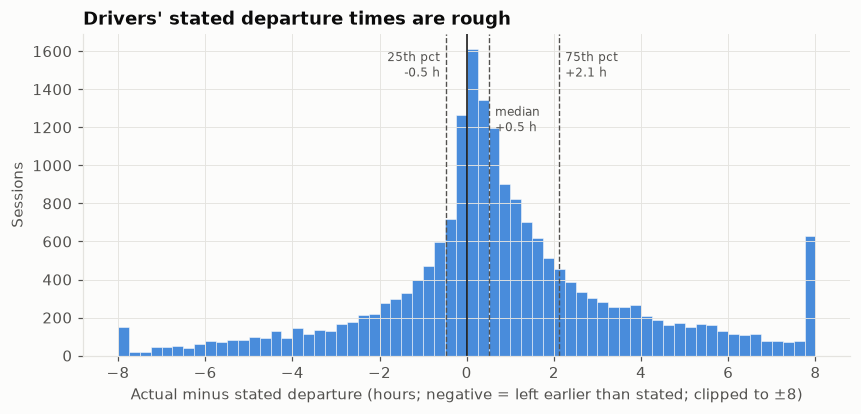

In [2]:
s = usable_sessions(load_clean("jpl"))
s = s[(s["connectionTime"] >= pd.Timestamp("2019-01-01", tz="America/Los_Angeles")) &
      (s["connectionTime"] < pd.Timestamp("2020-03-01", tz="America/Los_Angeles"))]
err = ((s["disconnectTime"] - s["requestedDeparture_first"]).dt.total_seconds() / 3600).dropna()
print(f"{len(err)} sessions with a stated departure ({len(err) / len(s):.0%}); "
      f"off by more than 2 h: {(err.abs() > 2).mean():.0%}; left earlier than stated: {(err < 0).mean():.0%}")
fig = plots.departure_error_hist(err)
save(fig, "online_departure_error")

## 2. Summary: median over weekdays

In [3]:
summary = res.groupby("policy").agg(
    peak_kw=("peak_kw", "median"),
    unmet_pct=("unmet_frac", lambda x: 100 * x.median()),
    mean_unmet_pct=("unmet_frac", lambda x: 100 * x.mean()),
    days_with_unmet_pct=("unmet_kwh", lambda x: 100 * (x > 0.01).mean()),
    sessions_short=("n_sessions_unmet", "median"),
)
order = (["offline_lp", "mpc_true", "mpc_driver", "mpc_conservative", "mpc_none"]
         + [f"mpc_driver_rmin{a}A" for a in (8, 12, 16)] + [f"mpc_none_rmin{a}A" for a in (8, 12, 16)]
         + ["equal_share_at_mpc_driver_peak"] + [p for p in summary.index if p.startswith("equal_share_x")]
         + ["uncontrolled"])
summary = summary.reindex([p for p in order if p in summary.index])
display(summary.round(2))

,peak_kw,unmet_pct,mean_unmet_pct,days_with_unmet_pct,sessions_short
policy,,,,,
offline_lp,84.36,0.00,0.00,0.00,0.0
mpc_true,118.58,0.00,0.00,0.00,0.0
mpc_driver,97.75,10.20,10.90,100.00,23.0
mpc_conservative,112.06,5.46,6.34,100.00,14.0
mpc_none,44.45,50.33,51.12,100.00,68.0
mpc_driver_rmin8A,105.31,2.98,4.10,100.00,12.0
mpc_driver_rmin12A,130.48,0.95,1.71,99.66,8.0
mpc_driver_rmin16A,156.17,0.41,0.90,99.66,7.0
mpc_none_rmin8A,81.71,16.06,16.68,100.00,30.0


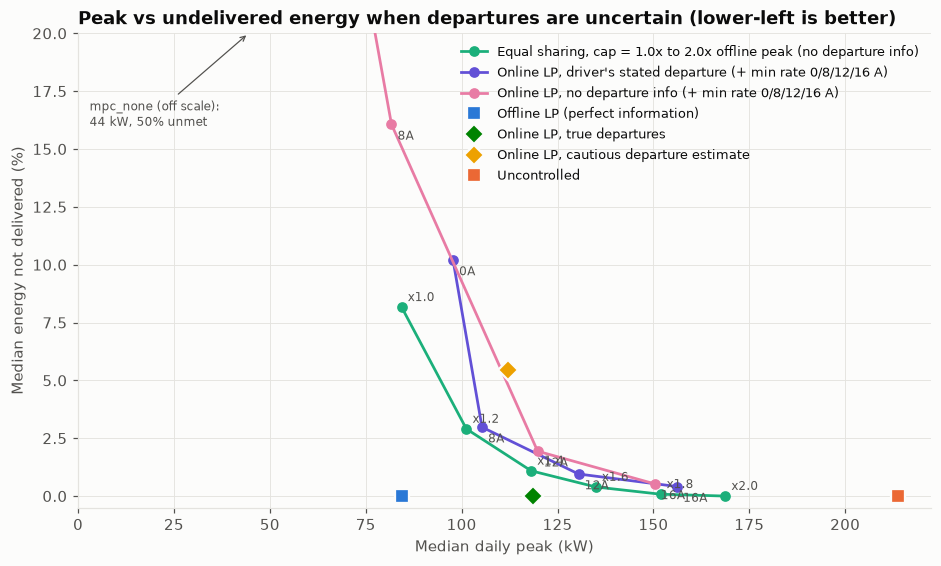

In [4]:
fig = plots.online_frontier(summary)
save(fig, "online_frontier")

## 3. Where does the gap come from?

In [5]:
def row(p):
    return summary.loc[p, ["peak_kw", "unmet_pct"]]
steps = pd.DataFrame({
    "offline (perfect info)": row("offline_lp"),
    "+ unknown arrivals": row("mpc_true"),
    "+ driver-stated departures": row("mpc_driver"),
    "+ 8 A minimum progress": row("mpc_driver_rmin8A"),
}).T
display(steps.round(2))
eq = summary.loc["equal_share_at_mpc_driver_peak"]
print(f"At the same peak as the online LP with driver estimates ({summary.loc['mpc_driver', 'peak_kw']:.0f} kW), "
      f"equal sharing leaves {eq['unmet_pct']:.1f}% unmet vs {summary.loc['mpc_driver', 'unmet_pct']:.1f}% for the online LP.")

,peak_kw,unmet_pct
offline (perfect info),84.36,0.00
+ unknown arrivals,118.58,0.00
+ driver-stated departures,97.75,10.20
+ 8 A minimum progress,105.31,2.98


At the same peak as the online LP with driver estimates (98 kW), equal sharing leaves 3.5% unmet vs 10.2% for the online LP.


## 4. Reading the results

Numbers below are medians over 297 JPL weekdays, from the tables above.

1. **Not knowing future arrivals costs peak, not energy.**
   - With true departures, the online LP delivers everything.
   - Its peak rises from 84 kW (offline) to 119 kW (+41%), because it can't save room for cars it hasn't seen yet.
2. **Trusting stated departures costs energy.**
   - With drivers' first estimates, the online LP leaves **10.2%** of energy undelivered at a 98 kW peak.
   - 35% of drivers leave earlier than they said, and a peak-minimizing controller *defers* charging, so it is hit hardest.
   - Shifting estimates earlier (cautious estimate) halves unmet energy to 5.5%, at a 112 kW peak.
3. **Equal sharing is the better online policy at JPL.**
   - At the same 98 kW peak it leaves **3.5%** unmet vs 10.2%.
   - Across the whole frontier, its curve sits at or below the online-LP curves:

     | Policy | Peak | Unmet |
     |---|---|---|
     | Equal sharing 1.2× | 101 kW | 2.9% |
     | Online LP + 8 A | 105 kW | 3.0% |
     | Equal sharing 1.4× | 118 kW | 1.1% |
     | Online LP + 12 A | 130 kW | 0.95% |

   - **Optimization is only as good as its information:** with noisy departures, a simple rule that never defers anyone matches or beats it.
4. **A minimum-progress guarantee is a cheap hedge for the online LP.** 8 A cuts unmet from 10.2% to 3.0% for +8 kW of peak, which brings the online LP roughly onto the equal-sharing curve.
5. **Drivers' estimates are worth something, but not much.** At equal minimum rates, stated departures beat "no departure info": at 8 A, 3.0% vs 16.1% unmet, at slightly higher peak. At 12–16 A the two curves nearly merge.

**What would make optimization win online?** The gap between the offline LP and every online policy is the value of better information. Ideas for future work:
- learn per-driver departure distributions from `userID` history;
- plan against departure scenarios, as in Puech et al. 2024 / Tucker et al. 2022 (see `LITERATURE.md`);
- add a fairness or "don't defer" term to the online objective.